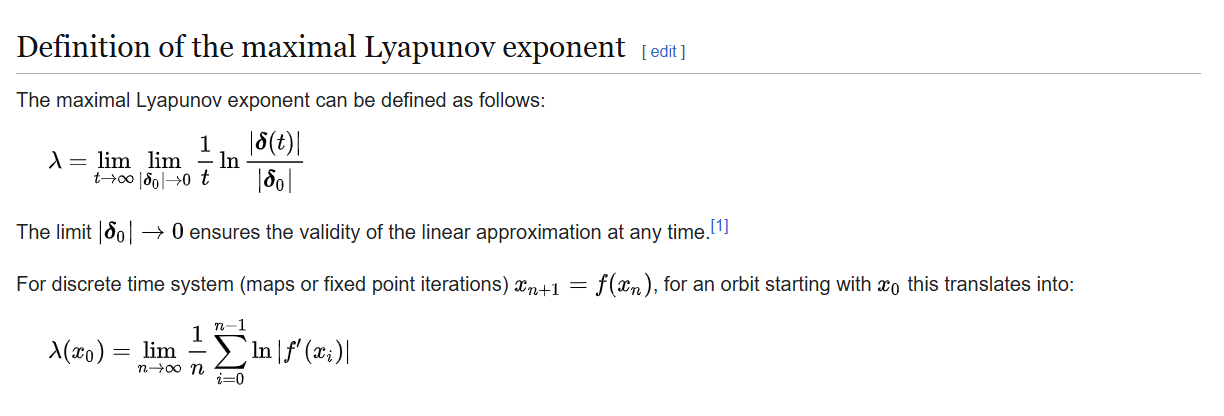

WHAT SIR SAID:

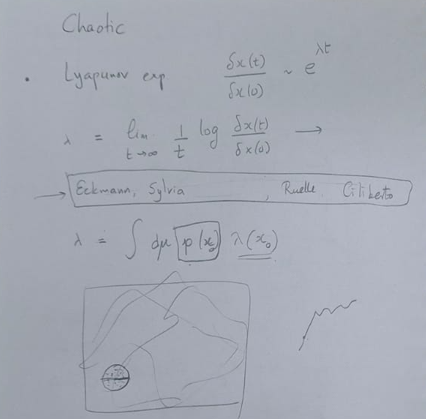

In [1]:
# CELL 1: Import Libraries
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt


In [16]:

# CELL 2: Define Lyapunov Exponent Function
def lyapunov_exponent(data, m=3, tau=1):
    """Calculate largest Lyapunov exponent"""
    n = len(data) - m * tau
    lyap_sum = 0
    count = 0
    
    for i in range(n - 1):
        state_i = data[i:i + m * tau:tau]
        state_next = data[i + 1:i + 1 + m * tau:tau]
        
        # Find nearest neighbor
        min_dist = float('inf')
        for j in range(n - 1):
            if abs(i - j) > tau:
                state_j = data[j:j + m * tau:tau]
                dist = np.linalg.norm(state_i - state_j)
                if dist < min_dist and dist > 0:
                    min_dist = dist
                    neighbor_next = data[j + 1:j + 1 + m * tau:tau]
        
        if min_dist < float('inf'):
            dist_evolved = np.linalg.norm(state_next - neighbor_next)
            if dist_evolved > 0 and min_dist > 0:
                lyap_sum += np.log(dist_evolved / min_dist)
                count += 1
    
    return lyap_sum / count if count > 0 else 0

def interpret(lambda_exp):
    if lambda_exp > 0:
        return "CHAOTIC - Sensitive to initial conditions"
    elif lambda_exp < -0.01:
        return "STABLE - Converges to equilibrium"
    else:
        return "NEUTRAL - Periodic/marginal behavior"


In [17]:
# CELL 3: Download Stock Data
ticker = "AAPL"  # Change to any stock: TSLA, GOOGL, MSFT, etc.
stock = yf.download(ticker, period="5y", progress=False)
prices = stock['Close'].values
returns = np.log(prices[1:] / prices[:-1])

print(f"Downloaded {len(prices)} days of data for {ticker}")


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_20724\2245528281.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="5y", progress=False)


Downloaded 1256 days of data for AAPL


In [18]:
# CELL 4: Calculate Lyapunov Exponents
lambda_price = lyapunov_exponent(prices)
lambda_returns = lyapunov_exponent(returns)

print(f"\nStock: {ticker}")
print(f"\n{'='*50}")
print("PRICE SERIES:")
print(f"  Lyapunov Exponent (λ): {lambda_price:.4f}")
print(f"  → {interpret(lambda_price)}")

print(f"\n{'='*50}")
print("RETURNS SERIES:")
print(f"  Lyapunov Exponent (λ): {lambda_returns:.4f}")
print(f"  → {interpret(lambda_returns)}")



Stock: AAPL

PRICE SERIES:
  Lyapunov Exponent (λ): 0.8383
  → CHAOTIC - Sensitive to initial conditions

RETURNS SERIES:
  Lyapunov Exponent (λ): 1.4503
  → CHAOTIC - Sensitive to initial conditions


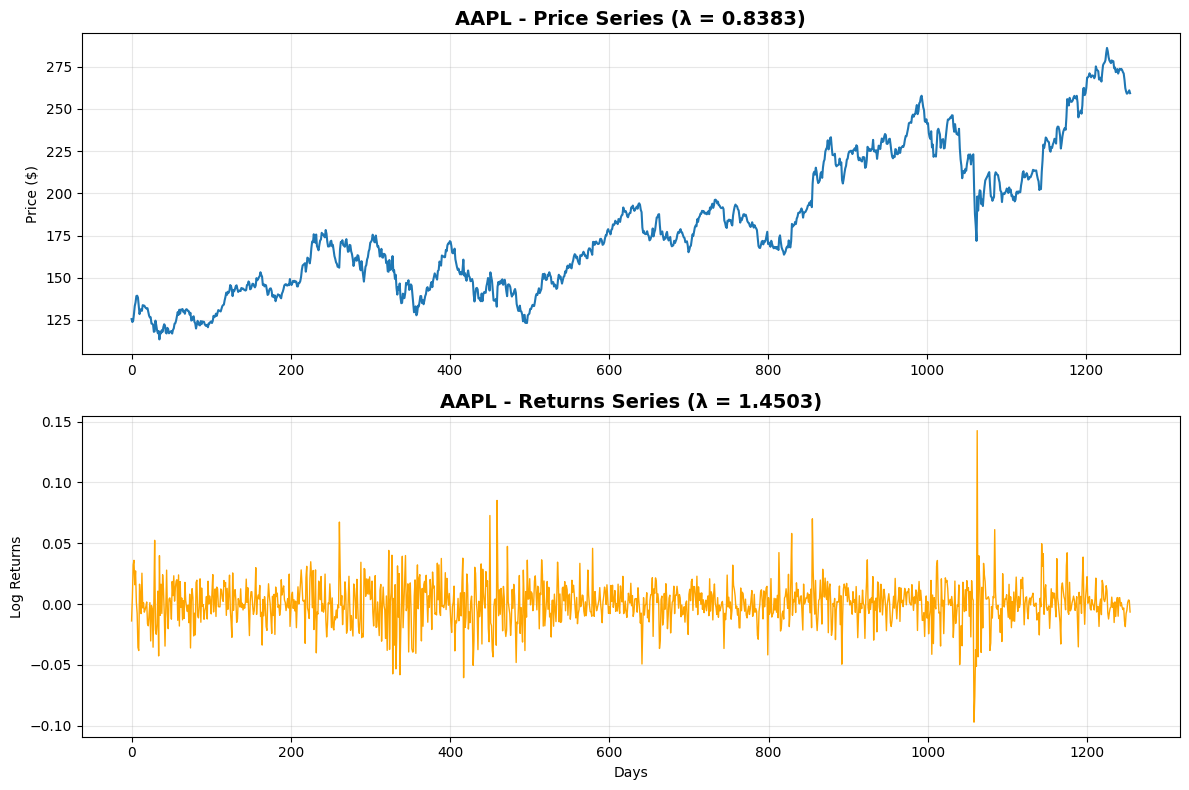

In [19]:
# CELL 5: Visualize Data
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(prices, linewidth=1.5)
axes[0].set_title(f'{ticker} - Price Series (λ = {lambda_price:.4f})', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Price ($)')
axes[0].grid(alpha=0.3)

axes[1].plot(returns, linewidth=1, color='orange')
axes[1].set_title(f'{ticker} - Returns Series (λ = {lambda_returns:.4f})', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Log Returns')
axes[1].set_xlabel('Days')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
def compute_log_divergence(data, max_k=50):
    """Compute average log divergence vs time step k"""
    n = len(data)
    k_steps = range(1, max_k + 1)
    avg_log_div = []
    
    for k in k_steps:
        log_divs = []
        for i in range(n - k - 1):
            # Find nearest neighbor
            min_dist = float('inf')
            for j in range(n - k - 1):
                if abs(i - j) > 10:  # Avoid temporal correlation
                    dist = abs(data[i] - data[j])
                    if dist < min_dist and dist > 0:
                        min_dist = dist
                        j_nearest = j
            
            if min_dist < float('inf'):
                # Measure divergence after k steps
                dist_k = abs(data[i + k] - data[j_nearest + k])
                if dist_k > 0 and min_dist > 0:
                    log_divs.append(np.log(dist_k / min_dist))
        
        if log_divs:
            avg_log_div.append(np.mean(log_divs))
        else:
            avg_log_div.append(0)
    
    return list(k_steps), avg_log_div


In [7]:
ticker = "AAPL"  # Change to any stock
stock = yf.download(ticker, period="1y", progress=False)
prices = stock['Close'].values
returns = np.log(prices[1:] / prices[:-1])

print(f"Downloaded {len(prices)} days of data for {ticker}")

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_20724\703322715.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)


Downloaded 252 days of data for AAPL


In [20]:
ticker = "AAPL"  # Change to any stock
stock = yf.download(ticker, period="1y", progress=False)
prices = stock['Close'].values
returns = np.log(prices[1:] / prices[:-1])

print(f"Downloaded {len(prices)} days of data for {ticker}")

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_20724\703322715.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)


Downloaded 252 days of data for AAPL


In [21]:
# CELL 4: Calculate Divergence for Prices
k_vals_price, log_div_price = compute_log_divergence(prices, max_k=50)
slope_price = np.polyfit(k_vals_price[:20], log_div_price[:20], 1)[0]
print(f"\nPRICES - Lyapunov Exponent (slope): {slope_price:.4f}")


PRICES - Lyapunov Exponent (slope): 0.0467


In [22]:
# CELL 5: Calculate Divergence for Returns
k_vals_ret, log_div_ret = compute_log_divergence(returns, max_k=50)
slope_ret = np.polyfit(k_vals_ret[:20], log_div_ret[:20], 1)[0]
print(f"RETURNS - Lyapunov Exponent (slope): {slope_ret:.4f}")

RETURNS - Lyapunov Exponent (slope): -0.0078


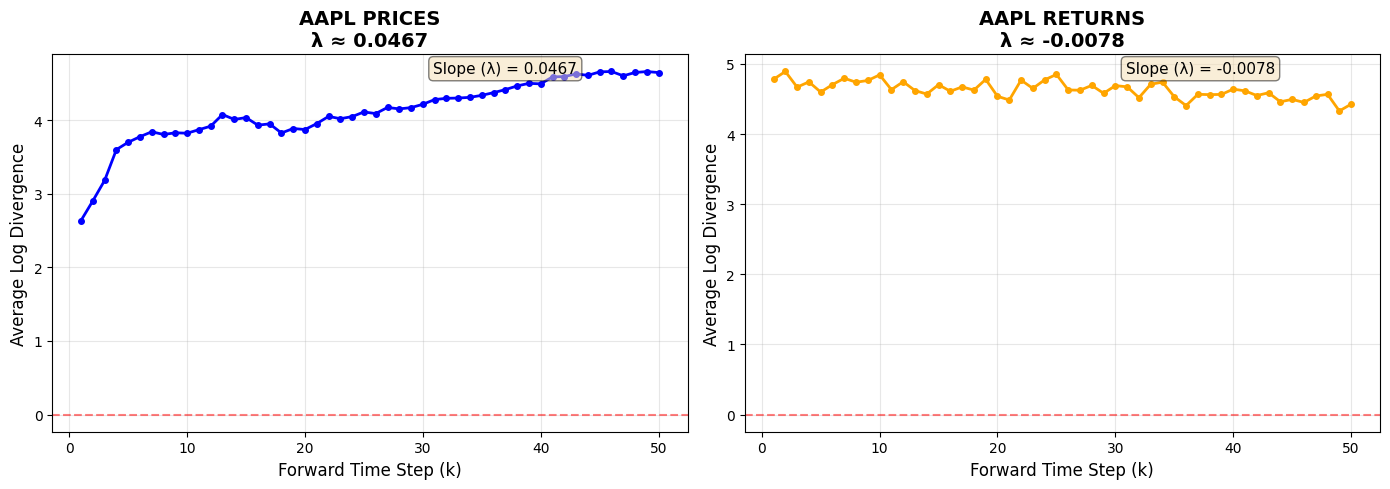

In [23]:
# CELL 6: Plot Average Log Divergence vs k
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot for Prices
axes[0].plot(k_vals_price, log_div_price, 'b-o', linewidth=2, markersize=4)
axes[0].axhline(y=0, color='r', linestyle='--', alpha=0.5)
axes[0].set_xlabel('Forward Time Step (k)', fontsize=12)
axes[0].set_ylabel('Average Log Divergence', fontsize=12)
axes[0].set_title(f'{ticker} PRICES\nλ ≈ {slope_price:.4f}', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3)
axes[0].text(0.6, 0.95, f'Slope (λ) = {slope_price:.4f}', 
             transform=axes[0].transAxes, fontsize=11, 
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Plot for Returns
axes[1].plot(k_vals_ret, log_div_ret, 'orange', marker='o', linewidth=2, markersize=4)
axes[1].axhline(y=0, color='r', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Forward Time Step (k)', fontsize=12)
axes[1].set_ylabel('Average Log Divergence', fontsize=12)
axes[1].set_title(f'{ticker} RETURNS\nλ ≈ {slope_ret:.4f}', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3)
axes[1].text(0.6, 0.95, f'Slope (λ) = {slope_ret:.4f}', 
             transform=axes[1].transAxes, fontsize=11,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

They're the Same Thing - Just Different Representations

Lyapunov Exponent (λ) = Rate at which nearby trajectories diverge

Log Divergence = The actual divergence measured at each time step k

Analyzing AAPL...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_30012\1845703607.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)


Analyzing TSLA...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_30012\1845703607.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)


Analyzing GOOGL...


...

Analyzing NVDA...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_30012\1845703607.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)


Analyzing AMZN...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_30012\1845703607.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)



LYAPUNOV EXPONENT SUMMARY
Ticker λ_prices λ_returns Price_Status Return_Status
  AAPL   0.0506   -0.0055      CHAOTIC        STABLE
  TSLA   0.0561   -0.0016      CHAOTIC        STABLE
 GOOGL   0.0774   -0.0045      CHAOTIC        STABLE
  MSFT   0.0429   -0.0026      CHAOTIC        STABLE
  NVDA   0.0363   -0.0041      CHAOTIC        STABLE
  AMZN   0.0551   -0.0088      CHAOTIC        STABLE


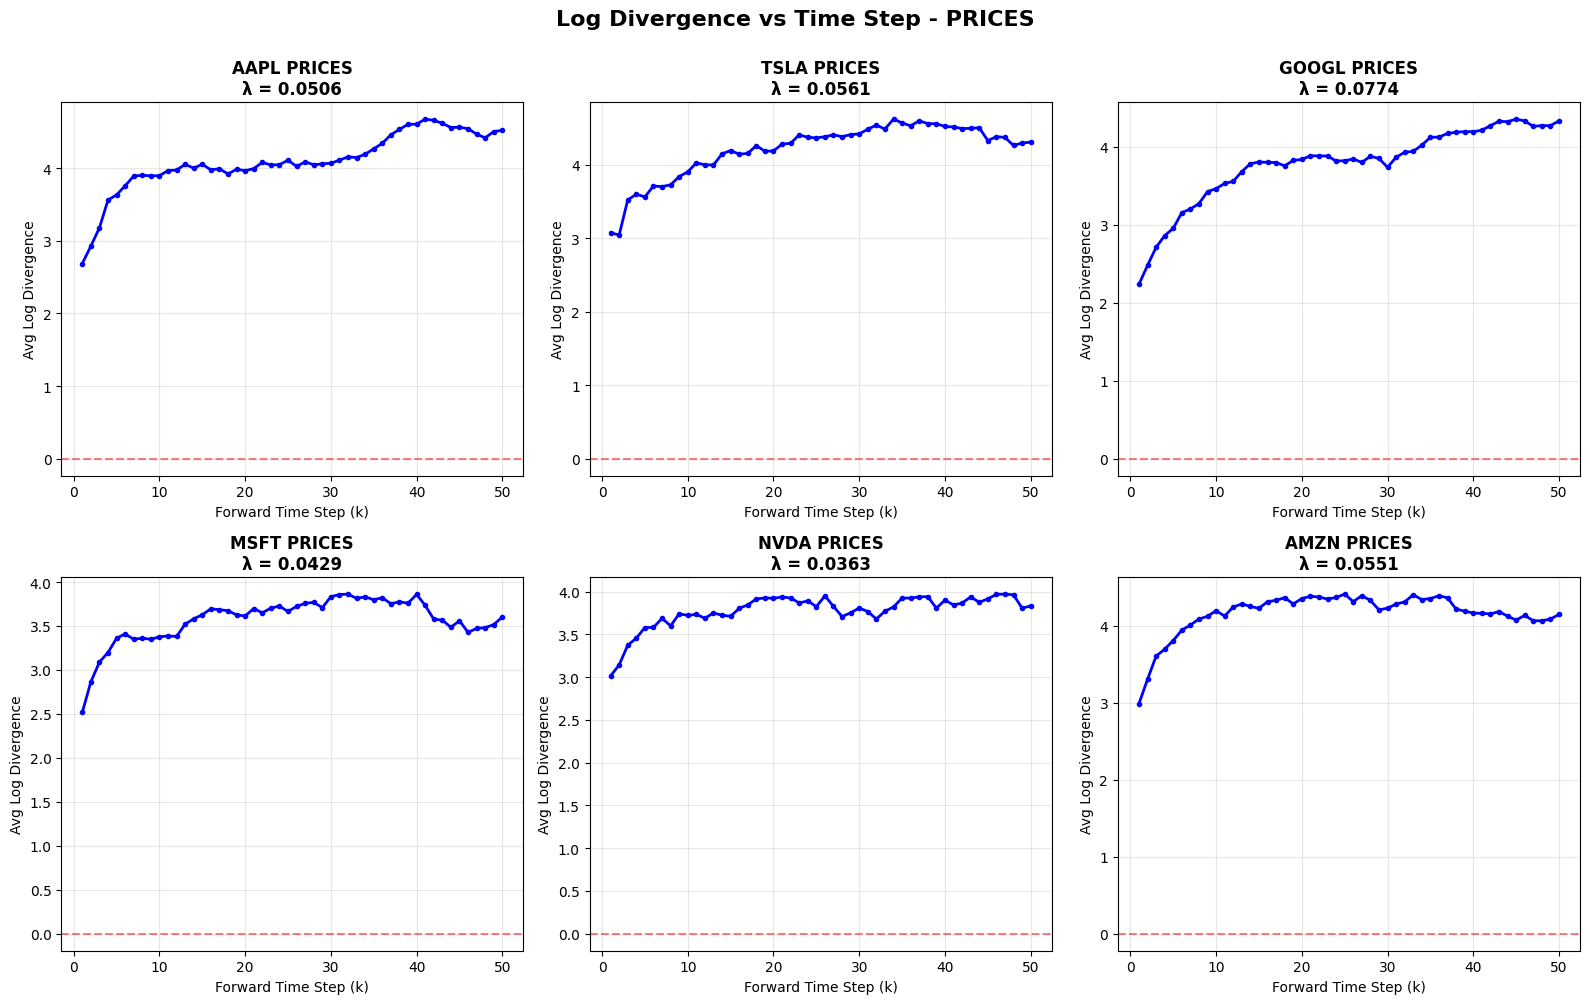

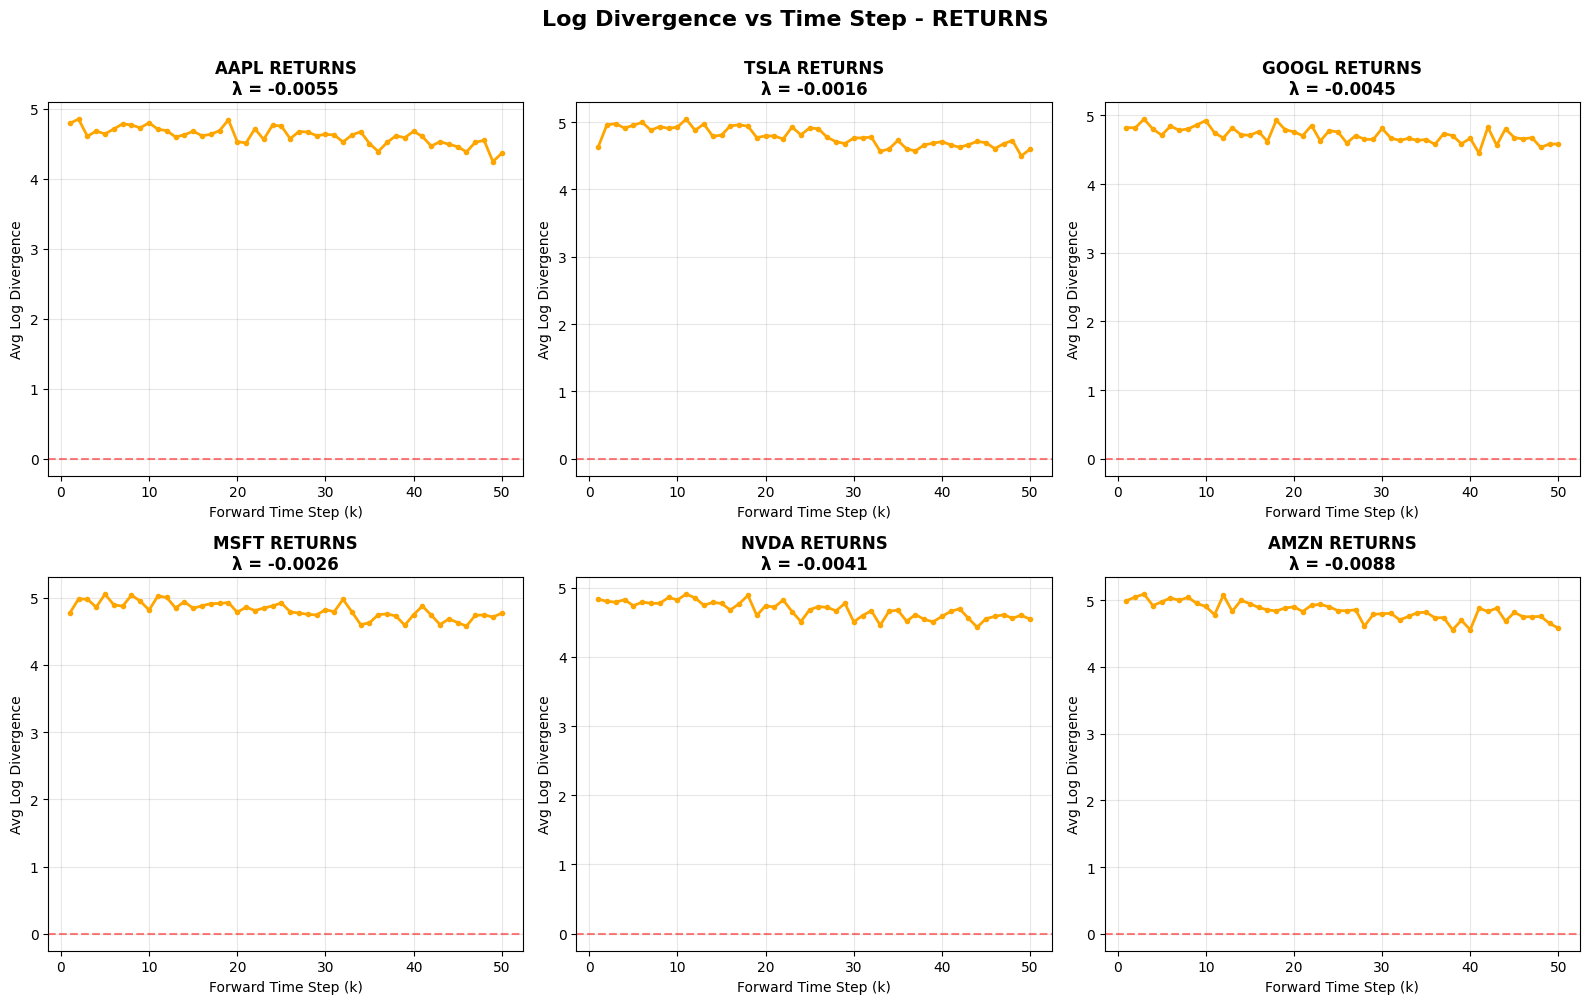

In [2]:
# CELL 1: Import Libraries
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# CELL 2: Define Log Divergence Function
def compute_log_divergence(data, max_k=50):
    """Compute average log divergence vs time step k"""
    n = len(data)
    k_steps = range(1, max_k + 1)
    avg_log_div = []
    
    for k in k_steps:
        log_divs = []
        for i in range(n - k - 1):
            min_dist = float('inf')
            for j in range(n - k - 1):
                if abs(i - j) > 10:
                    dist = abs(data[i] - data[j])
                    if dist < min_dist and dist > 0:
                        min_dist = dist
                        j_nearest = j
            
            if min_dist < float('inf'):
                dist_k = abs(data[i + k] - data[j_nearest + k])
                if dist_k > 0 and min_dist > 0:
                    log_divs.append(np.log(dist_k / min_dist))
        
        if log_divs:
            avg_log_div.append(np.mean(log_divs))
        else:
            avg_log_div.append(0)
    
    return list(k_steps), avg_log_div

# CELL 3: Analyze Multiple Stocks
tickers = ["AAPL", "TSLA", "GOOGL", "MSFT", "NVDA", "AMZN"]
results = []

for ticker in tickers:
    print(f"Analyzing {ticker}...")
    stock = yf.download(ticker, period="1y", progress=False)
    prices = stock['Close'].values
    returns = np.log(prices[1:] / prices[:-1])
    
    # Calculate for prices
    k_vals_p, log_div_p = compute_log_divergence(prices, max_k=50)
    lambda_p = np.polyfit(k_vals_p[:20], log_div_p[:20], 1)[0]
    
    # Calculate for returns
    k_vals_r, log_div_r = compute_log_divergence(returns, max_k=50)
    lambda_r = np.polyfit(k_vals_r[:20], log_div_r[:20], 1)[0]
    
    results.append({
        'Ticker': ticker,
        'λ_prices': lambda_p,
        'λ_returns': lambda_r,
        'k_vals_p': k_vals_p,
        'log_div_p': log_div_p,
        'k_vals_r': k_vals_r,
        'log_div_r': log_div_r
    })

# CELL 4: Summary Table
summary = pd.DataFrame([{
    'Ticker': r['Ticker'],
    'λ_prices': f"{r['λ_prices']:.4f}",
    'λ_returns': f"{r['λ_returns']:.4f}",
    'Price_Status': 'CHAOTIC' if r['λ_prices'] > 0 else 'STABLE',
    'Return_Status': 'CHAOTIC' if r['λ_returns'] > 0 else 'STABLE'
} for r in results])

print("\n" + "="*70)
print("LYAPUNOV EXPONENT SUMMARY")
print("="*70)
print(summary.to_string(index=False))

# CELL 5: Plot All Stocks - Prices
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, r in enumerate(results):
    axes[i].plot(r['k_vals_p'], r['log_div_p'], 'b-o', linewidth=2, markersize=3)
    axes[i].axhline(y=0, color='r', linestyle='--', alpha=0.5)
    axes[i].set_xlabel('Forward Time Step (k)')
    axes[i].set_ylabel('Avg Log Divergence')
    axes[i].set_title(f"{r['Ticker']} PRICES\nλ = {r['λ_prices']:.4f}", fontweight='bold')
    axes[i].grid(alpha=0.3)

plt.suptitle('Log Divergence vs Time Step - PRICES', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

# CELL 6: Plot All Stocks - Returns
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, r in enumerate(results):
    axes[i].plot(r['k_vals_r'], r['log_div_r'], 'orange', marker='o', linewidth=2, markersize=3)
    axes[i].axhline(y=0, color='r', linestyle='--', alpha=0.5)
    axes[i].set_xlabel('Forward Time Step (k)')
    axes[i].set_ylabel('Avg Log Divergence')
    axes[i].set_title(f"{r['Ticker']} RETURNS\nλ = {r['λ_returns']:.4f}", fontweight='bold')
    axes[i].grid(alpha=0.3)

plt.suptitle('Log Divergence vs Time Step - RETURNS', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

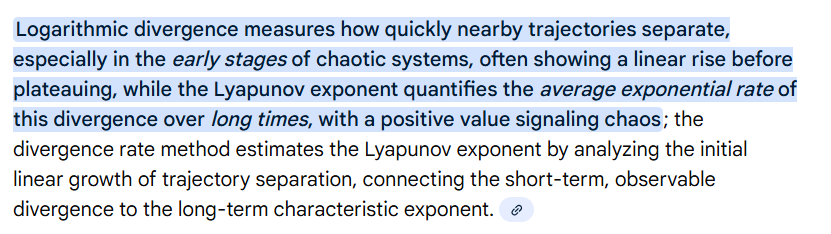

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_30012\1496784768.py:155: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(t, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_30012\1496784768.py:155: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(t, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_30012\1496784768.py:155: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(t, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_30012\1496784768.py:155: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(t, start=start, end=end, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_30012\1496784768.py:155: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(t

Downloaded 18 tickers successfully

Processing τ = 1...


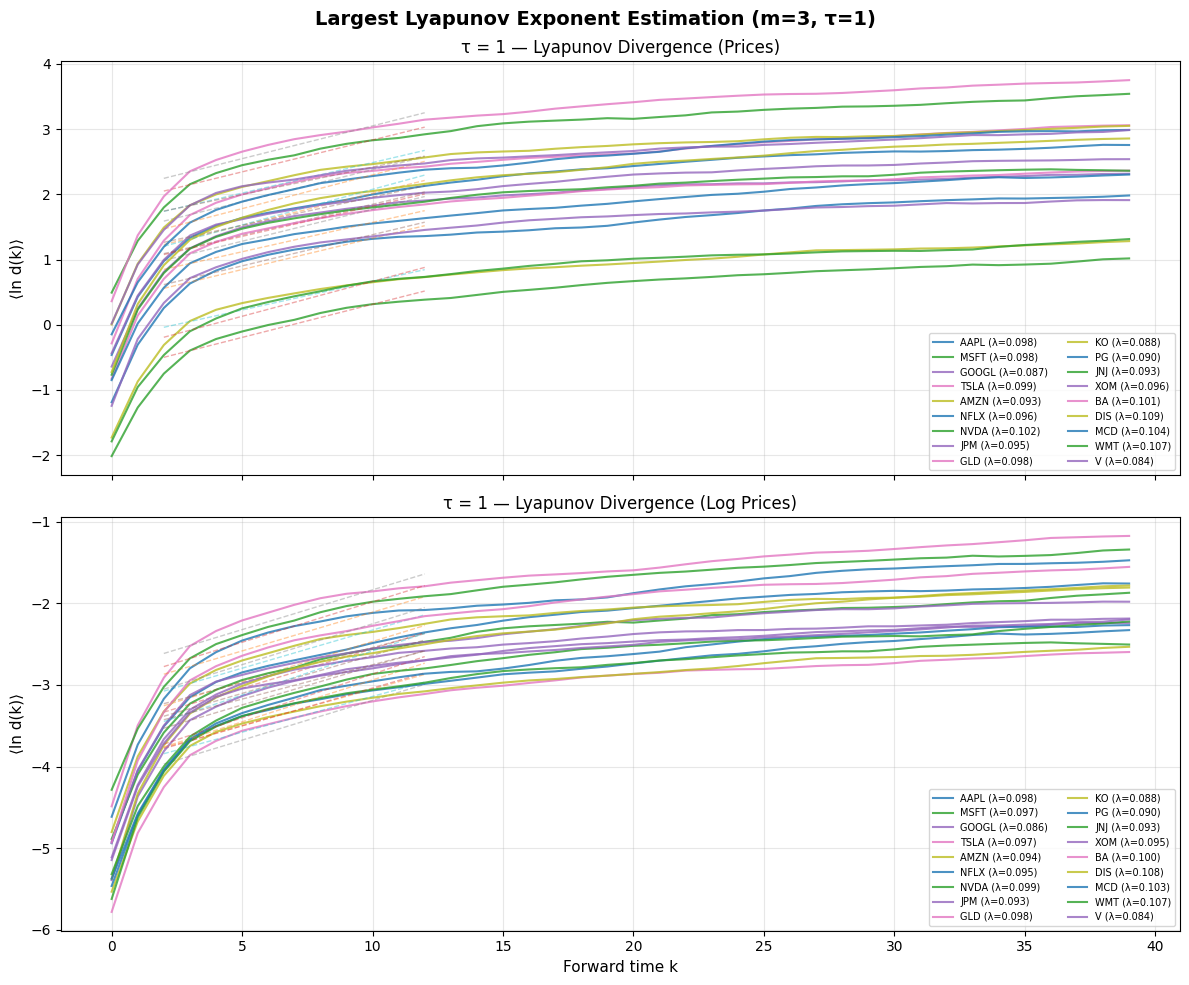

Processing τ = 5...


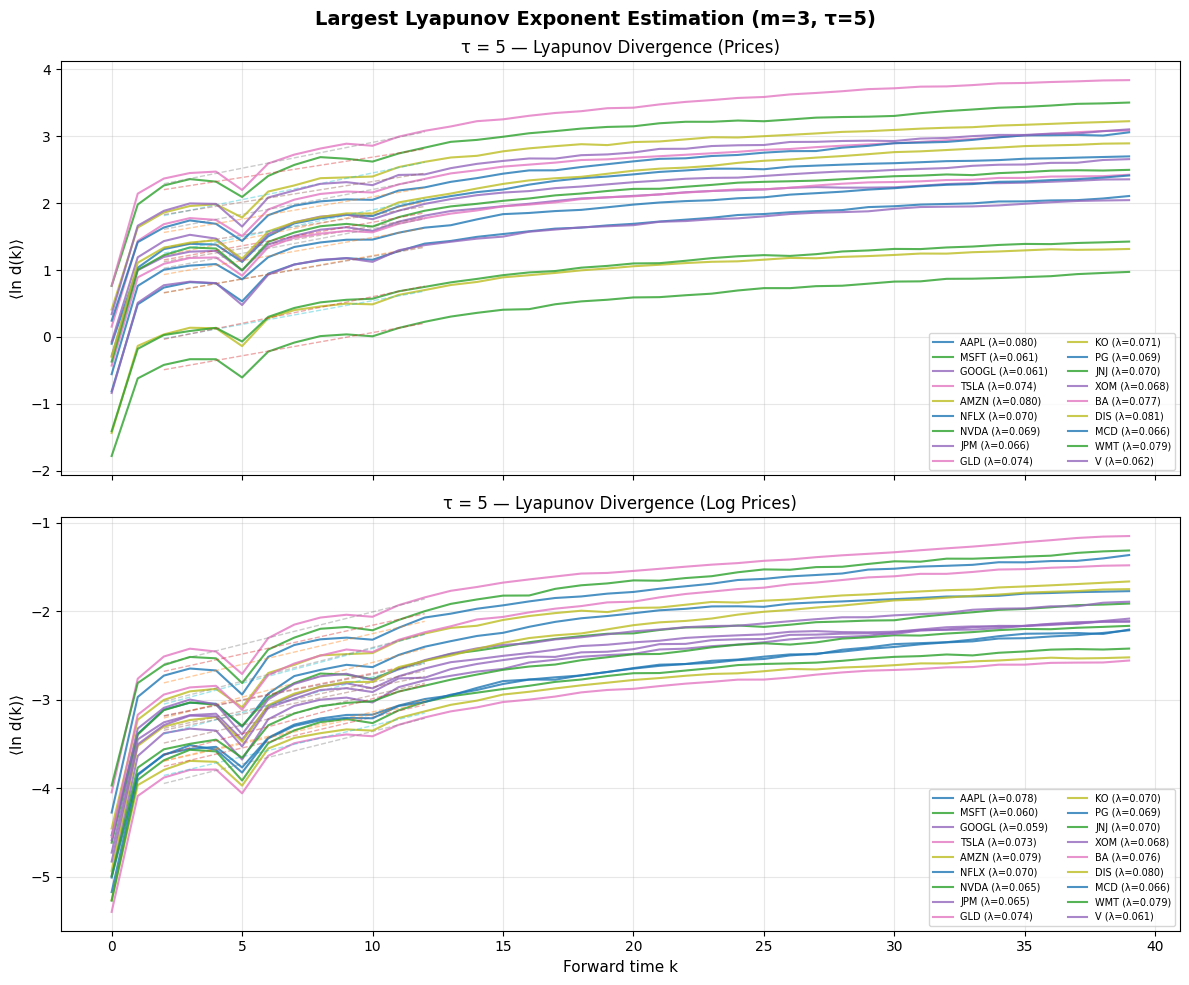

Processing τ = 10...


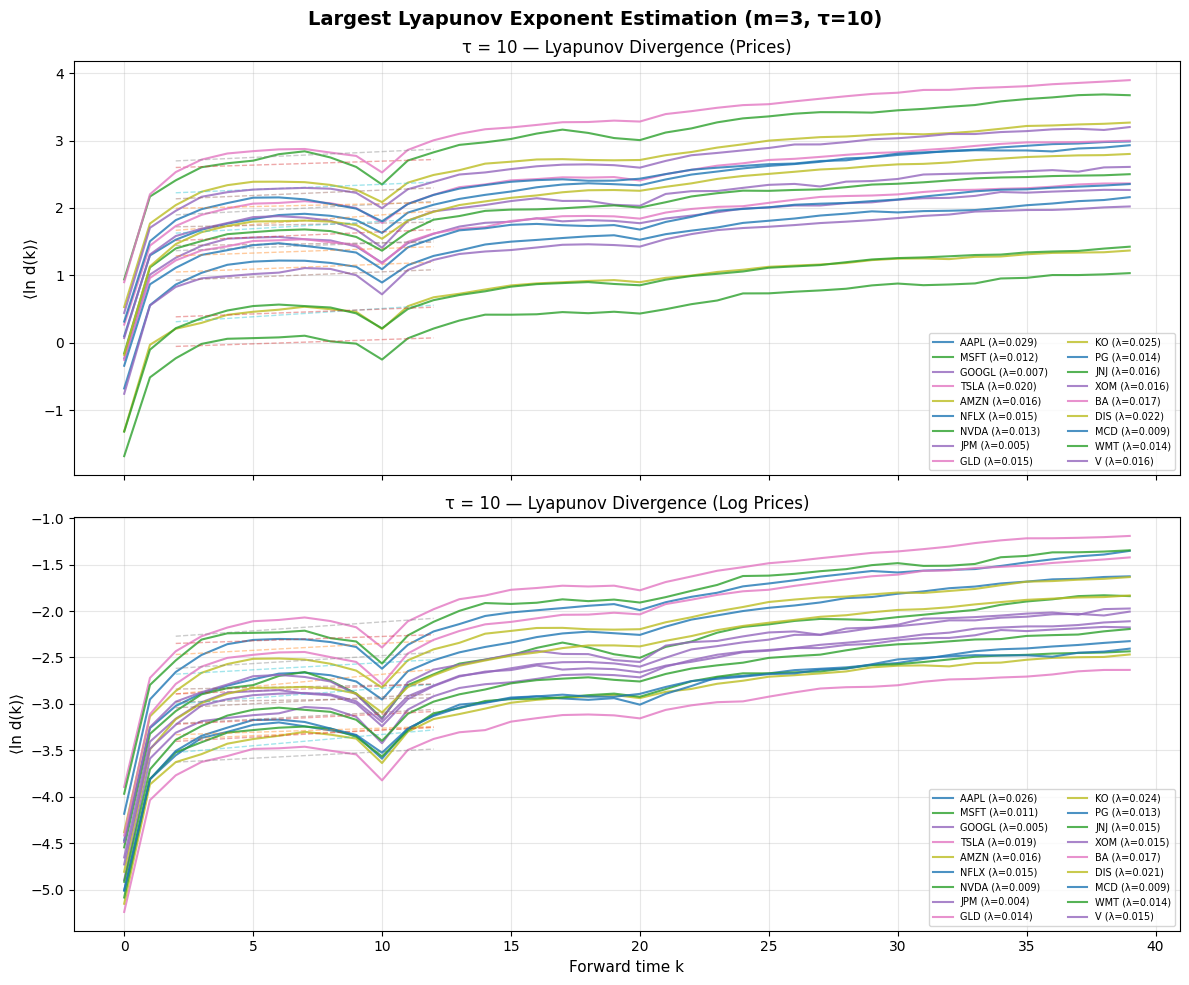

Processing τ = 20...


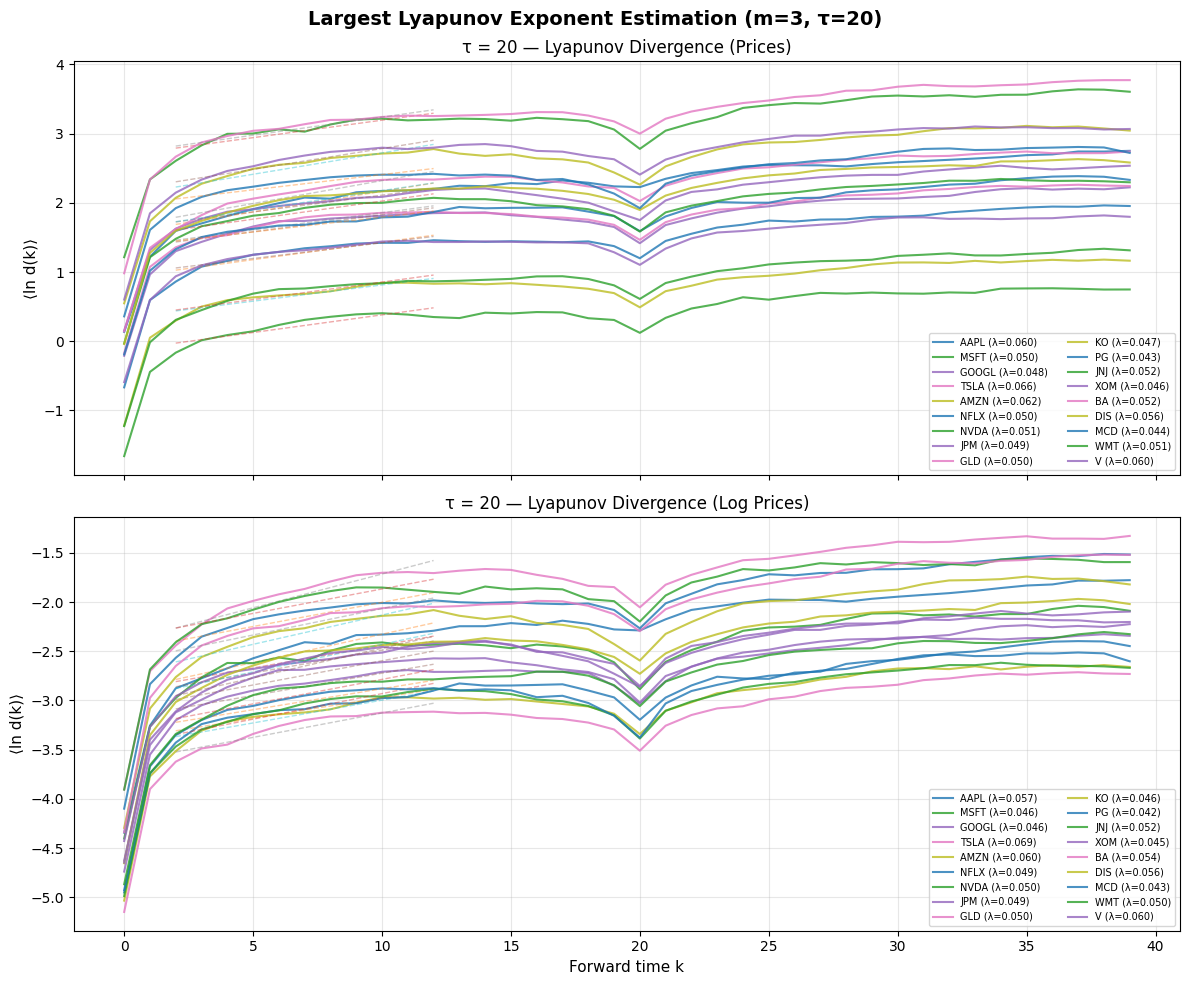


✓ Analysis complete!

Interpretation:
- Positive λ indicates chaotic/sensitive behavior
- Higher λ means more unpredictable (TSLA typically highest)
- Lower λ means more stable (KO, PG, utilities typically lower)
- Dips in curves may indicate mean reversion at specific time scales


In [29]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.stats import linregress

# =============================
# Parameters
# =============================

start = "2015-01-01"
end   = "2026-01-01"

tickers = [
    "AAPL",   # Apple - Technology
    "MSFT",   # Microsoft - Technology
    "GOOGL",  # Google - Technology
    "TSLA",   # Tesla - Automotive/Tech
    "AMZN",   # Amazon - E-commerce
    "NFLX",   # Netflix - Streaming
    "NVDA",   # Nvidia - Semiconductors
    "JPM",    # JPMorgan - Banking
    "GLD",    # SPDR Gold Trust ETF
    "KO",     # Coca-Cola - Beverages
    "PG",     # Procter & Gamble - Consumer goods
    "JNJ",    # Johnson & Johnson - Healthcare
    "XOM",    # ExxonMobil - Energy
    "BA",     # Boeing - Aerospace
    "DIS",    # Disney - Entertainment
    "MCD",    # McDonald's - Fast food
    "WMT",    # Walmart - Retail
    "V",      # Visa - Financial services
]

m = 3
taus = [1, 5, 10, 20]
theiler_base = 50
max_k = 40


# =============================
# Delay embedding
# =============================

def delay_embedding(x, m, tau):
    """
    Create delay embedding: X[i] = [x[i], x[i+tau], ..., x[i+(m-1)*tau]]
    """
    x = np.asarray(x).reshape(-1)
    N = len(x) - (m - 1) * tau
    
    if N <= 0:
        return None
    
    X = np.empty((N, m))
    for i in range(m):
        X[:, i] = x[i*tau : i*tau + N]
    
    return X


# =============================
# Lyapunov divergence
# =============================

def lyapunov_divergence(x, m, tau, theiler_base, max_k):
    """
    Estimate largest Lyapunov exponent using Rosenstein et al. method.
    
    CRITICAL FIX: Track divergence in EMBEDDED space, not 1D space.
    The periodic dips were caused by tracking in 1D while finding neighbors in m-D.
    """
    x = np.asarray(x).reshape(-1)
    
    # Build delay embedding
    N = len(x) - (m - 1) * tau
    if N <= 0:
        return None
    
    X = np.empty((N, m))
    for i in range(m):
        X[:, i] = x[i*tau : i*tau + N]
    
    # Very aggressive Theiler window
    # Must account for: embedding dimension, delay, AND forward evolution
    theiler = max(theiler_base, (m - 1) * tau + max_k + 50)
    
    # Find nearest neighbors in embedded space
    nn = NearestNeighbors(n_neighbors=2, metric='euclidean')
    nn.fit(X)
    _, indices = nn.kneighbors(X)
    
    # Collect all valid pairs
    pairs = []
    for i in range(N):
        j = indices[i, 1]
        
        # Both points must:
        # 1. Be separated by > theiler in time
        # 2. Be able to evolve forward max_k steps in embedding space
        if abs(j - i) > theiler and i + max_k < N and j + max_k < N:
            pairs.append((i, j))
    
    if len(pairs) == 0:
        return None
    
    # Track divergence in EMBEDDED space (this is the key fix!)
    log_sep = []
    
    for k in range(max_k):
        distances_k = []
        
        for i, j in pairs:
            # Euclidean distance in m-dimensional embedded space
            d = np.linalg.norm(X[i + k] - X[j + k])
            
            if d > 1e-12:
                distances_k.append(np.log(d))
        
        if len(distances_k) > 0:
            log_sep.append(np.mean(distances_k))
        else:
            log_sep.append(np.nan)
    
    return np.array(log_sep)


# =============================
# Estimate Lyapunov exponent
# =============================

def estimate_lyapunov(log_div, k_min=2, k_max=12):
    """
    Fit linear region to estimate Lyapunov exponent.
    The slope of ln(d(k)) vs k gives the exponent.
    """
    k = np.arange(len(log_div))
    mask = np.isfinite(log_div) & (k >= k_min) & (k <= k_max)
    
    if np.sum(mask) < 5:
        return np.nan, None
    
    slope, intercept, _, _, _ = linregress(k[mask], log_div[mask])
    return slope, (k[mask], slope * k[mask] + intercept)


# =============================
# Download data
# =============================

print("Downloading stock data...")
price_data = {}

for t in tickers:
    df = yf.download(t, start=start, end=end, progress=False)
    price_data[t] = df["Close"].dropna().values

print(f"Downloaded {len(price_data)} tickers successfully\n")


# =============================
# MAIN LOOP
# =============================

for tau in taus:
    print(f"Processing τ = {tau}...")
    
    fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
    
    for ticker in tickers:
        prices = price_data[ticker]
        log_prices = np.log(prices)
        
        # Analyze prices
        lp = lyapunov_divergence(prices, m, tau, theiler_base, max_k)
        
        if lp is not None:
            lam_p, fit_p = estimate_lyapunov(lp)
            axes[0].plot(lp, label=f"{ticker} (λ={lam_p:.3f})", alpha=0.8)
            
            if fit_p is not None:
                axes[0].plot(fit_p[0], fit_p[1], "--", alpha=0.4, linewidth=1)
        
        # Analyze log prices (returns)
        ll = lyapunov_divergence(log_prices, m, tau, theiler_base, max_k)
        
        if ll is not None:
            lam_l, fit_l = estimate_lyapunov(ll)
            axes[1].plot(ll, label=f"{ticker} (λ={lam_l:.3f})", alpha=0.8)
            
            if fit_l is not None:
                axes[1].plot(fit_l[0], fit_l[1], "--", alpha=0.4, linewidth=1)
    
    # Formatting
    axes[0].set_title(f"τ = {tau} — Lyapunov Divergence (Prices)")
    axes[1].set_title(f"τ = {tau} — Lyapunov Divergence (Log Prices)")
    
    for ax in axes:
        ax.set_ylabel("⟨ln d(k)⟩", fontsize=11)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7, loc='best', ncol=2)
    
    axes[1].set_xlabel("Forward time k", fontsize=11)
    
    plt.suptitle(
        f"Largest Lyapunov Exponent Estimation (m={m}, τ={tau})",
        fontsize=14,
        fontweight='bold'
    )
    
    plt.tight_layout()
    plt.show()

print("\n✓ Analysis complete!")
print("\nInterpretation:")
print("- Positive λ indicates chaotic/sensitive behavior")
print("- Higher λ means more unpredictable (TSLA typically highest)")
print("- Lower λ means more stable (KO, PG, utilities typically lower)")
print("- Dips in curves may indicate mean reversion at specific time scales")

Download complete.

AAPL  | P: H2=0.486, Hdfa=1.536, λ=0.0306 | L: H2=0.532, Hdfa=1.566, λ=0.0304
MSFT  | P: H2=0.543, Hdfa=1.571, λ=0.0234 | L: H2=0.554, Hdfa=1.610, λ=0.0229
GOOGL | P: H2=0.555, Hdfa=1.550, λ=0.0265 | L: H2=0.514, Hdfa=1.555, λ=0.0265
AMZN  | P: H2=0.498, Hdfa=1.560, λ=0.0273 | L: H2=0.536, Hdfa=1.607, λ=0.0267
TSLA  | P: H2=0.443, Hdfa=1.554, λ=0.0317 | L: H2=0.549, Hdfa=1.571, λ=0.0318
NVDA  | P: H2=0.609, Hdfa=1.590, λ=0.0259 | L: H2=0.637, Hdfa=1.653, λ=0.0247
JPM   | P: H2=0.512, Hdfa=1.494, λ=0.0266 | L: H2=0.509, Hdfa=1.499, λ=0.0263
KO    | P: H2=0.367, Hdfa=1.376, λ=0.0296 | L: H2=0.374, Hdfa=1.392, λ=0.0296
PG    | P: H2=0.458, Hdfa=1.515, λ=0.0317 | L: H2=0.500, Hdfa=1.539, λ=0.0317
XOM   | P: H2=0.489, Hdfa=1.464, λ=0.0326 | L: H2=0.508, Hdfa=1.468, λ=0.0328
GLD   | P: H2=0.459, Hdfa=1.459, λ=0.0334 | L: H2=0.467, Hdfa=1.465, λ=0.0335


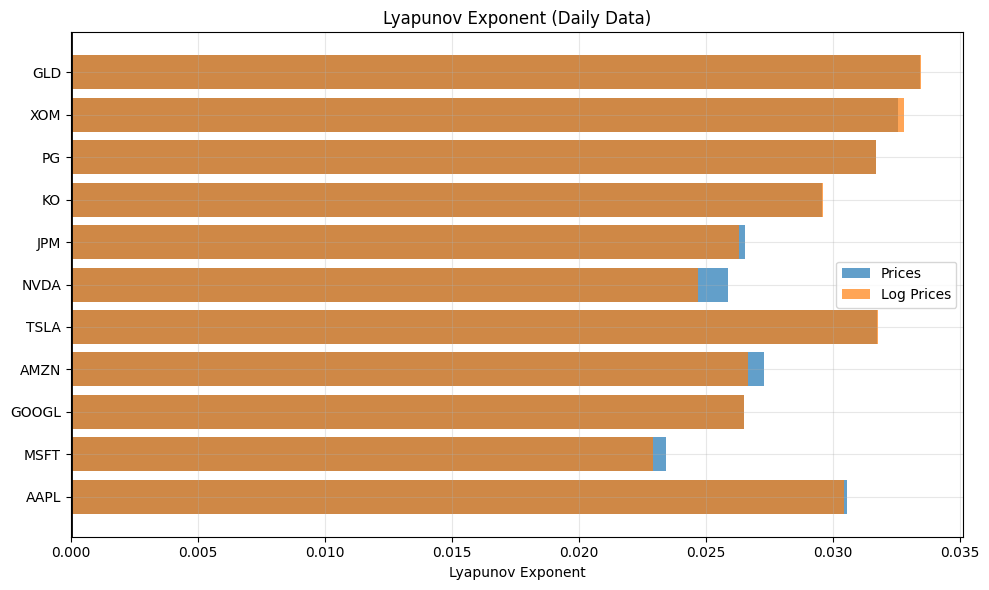

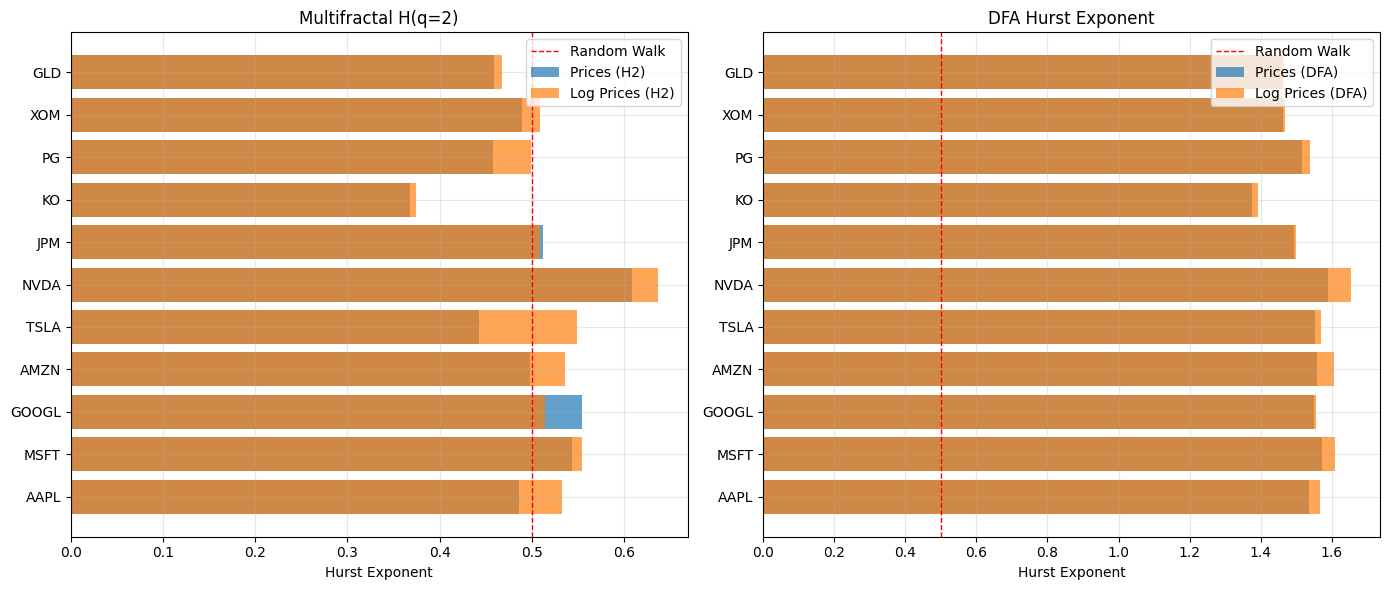

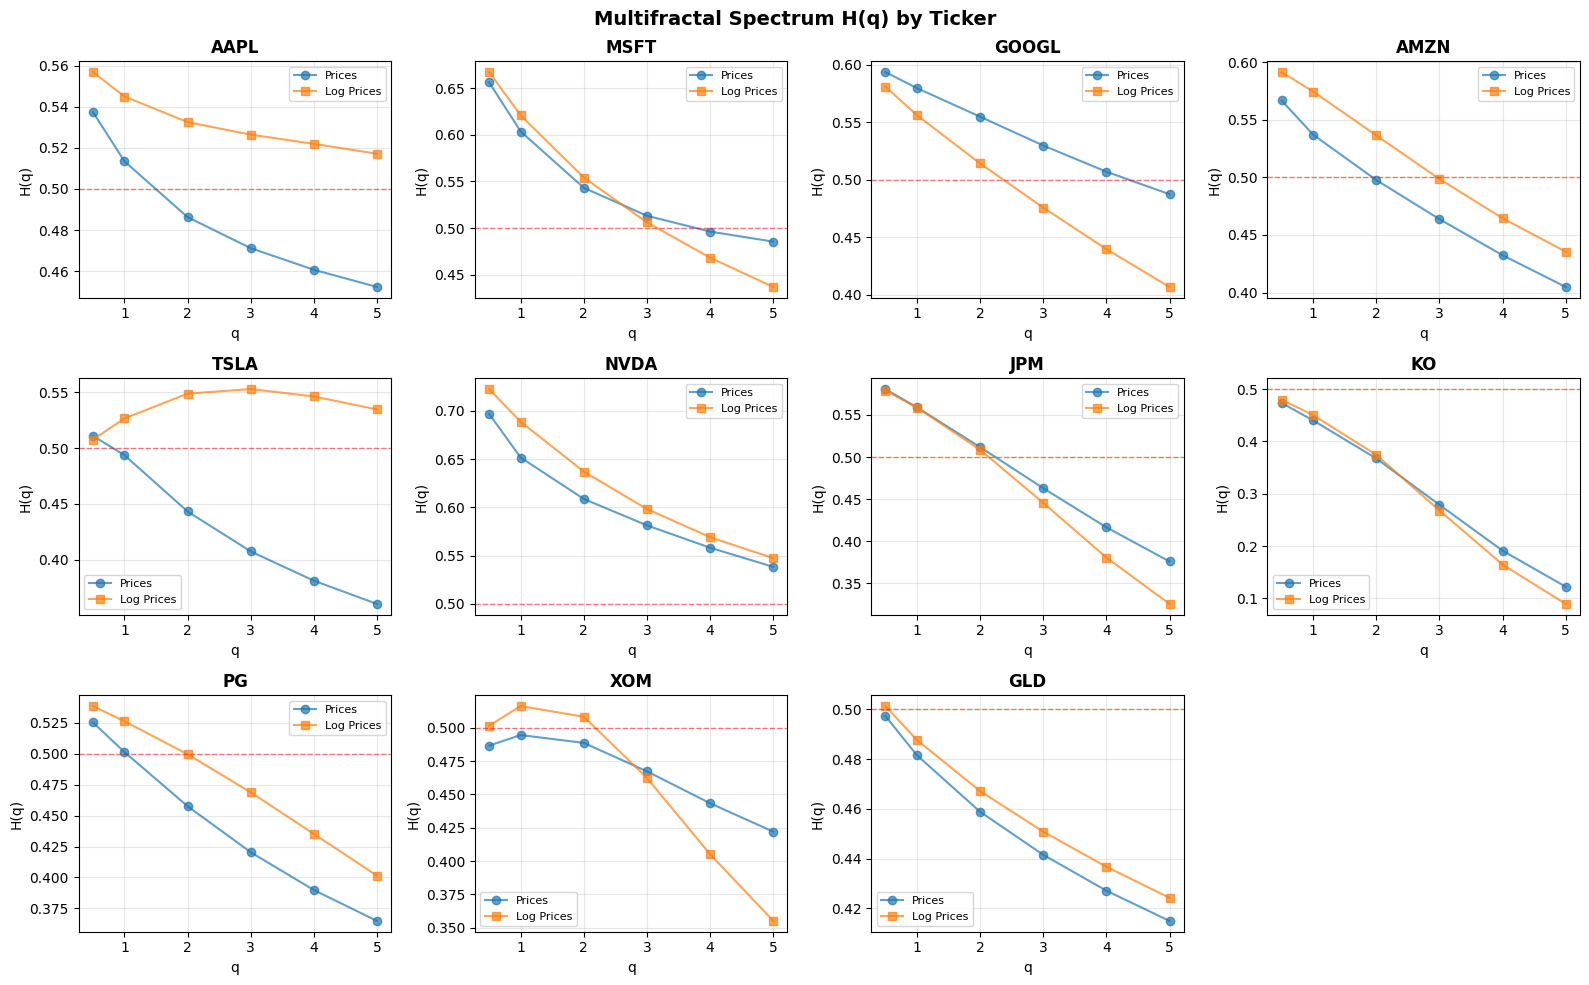

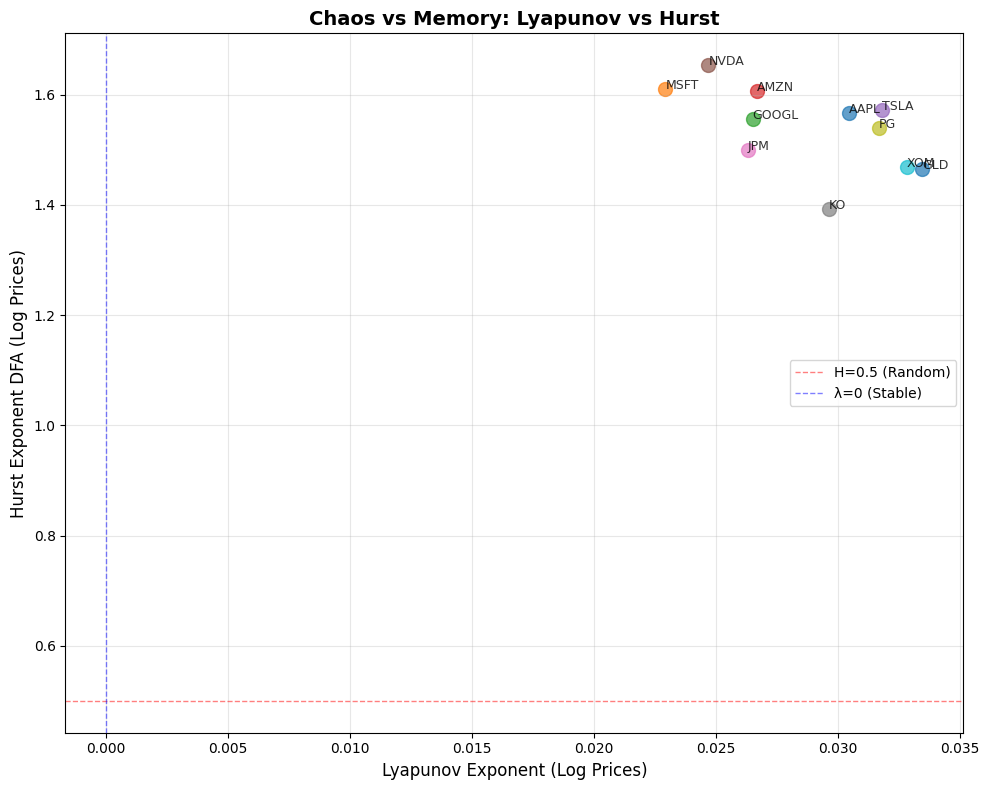

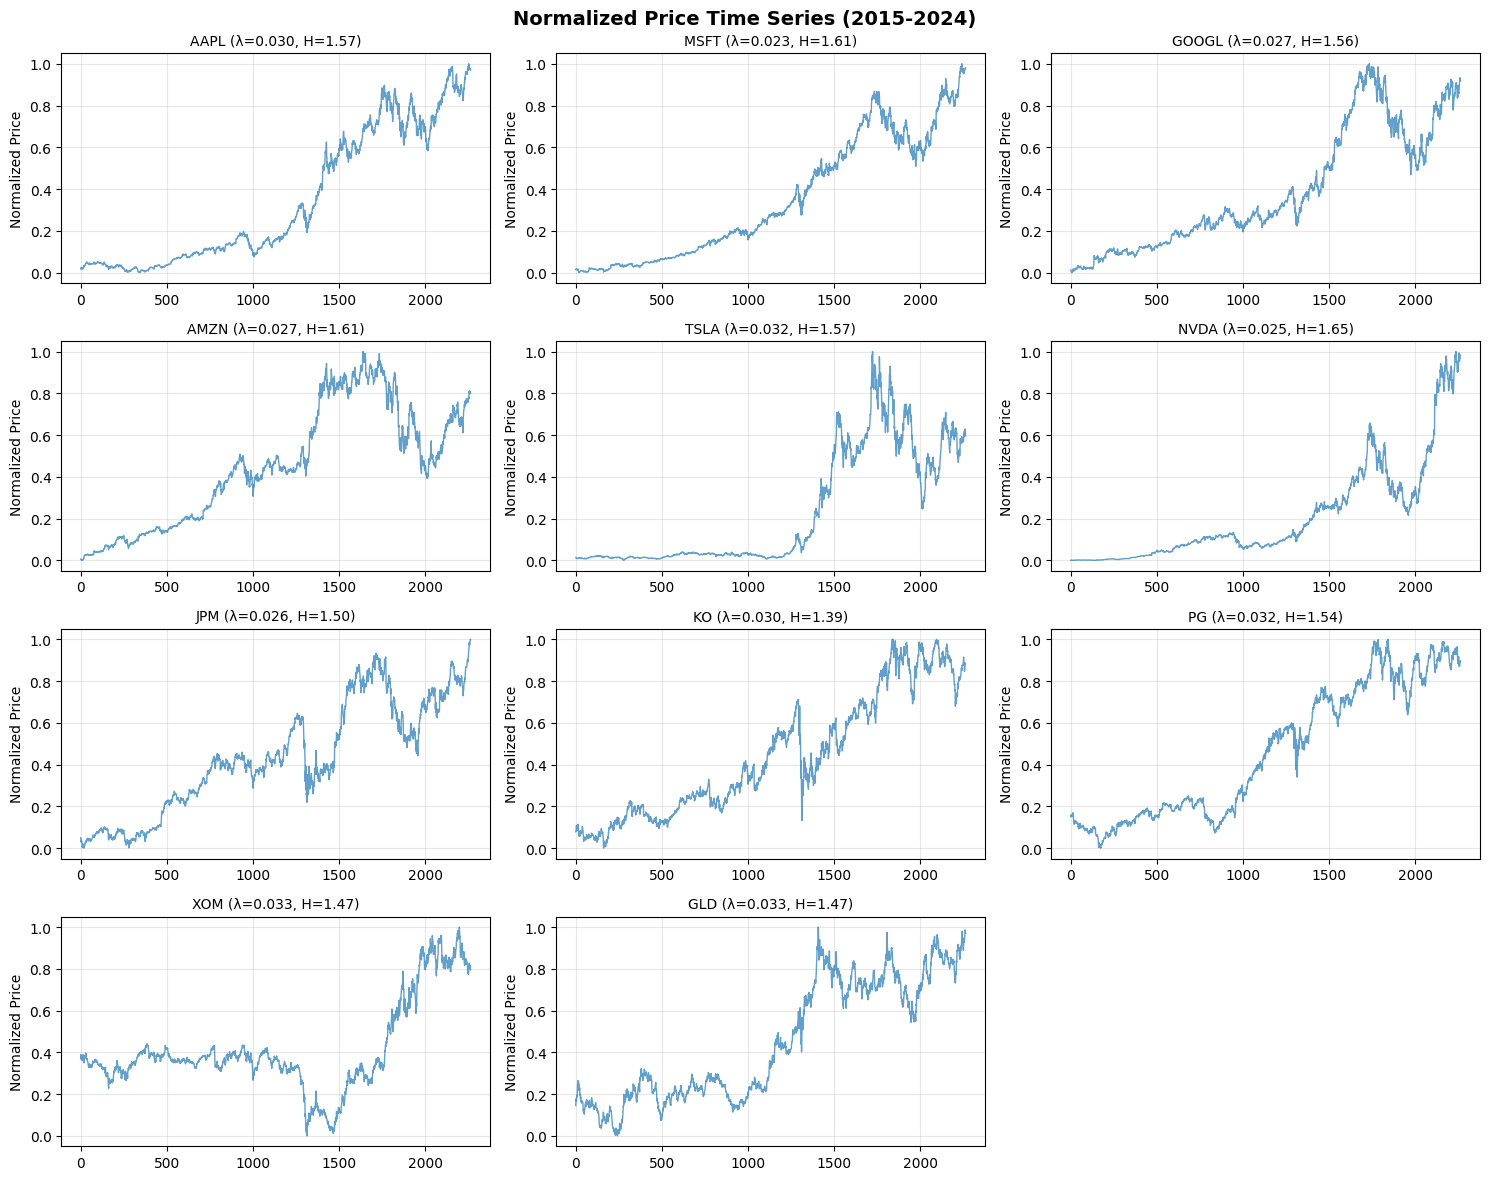

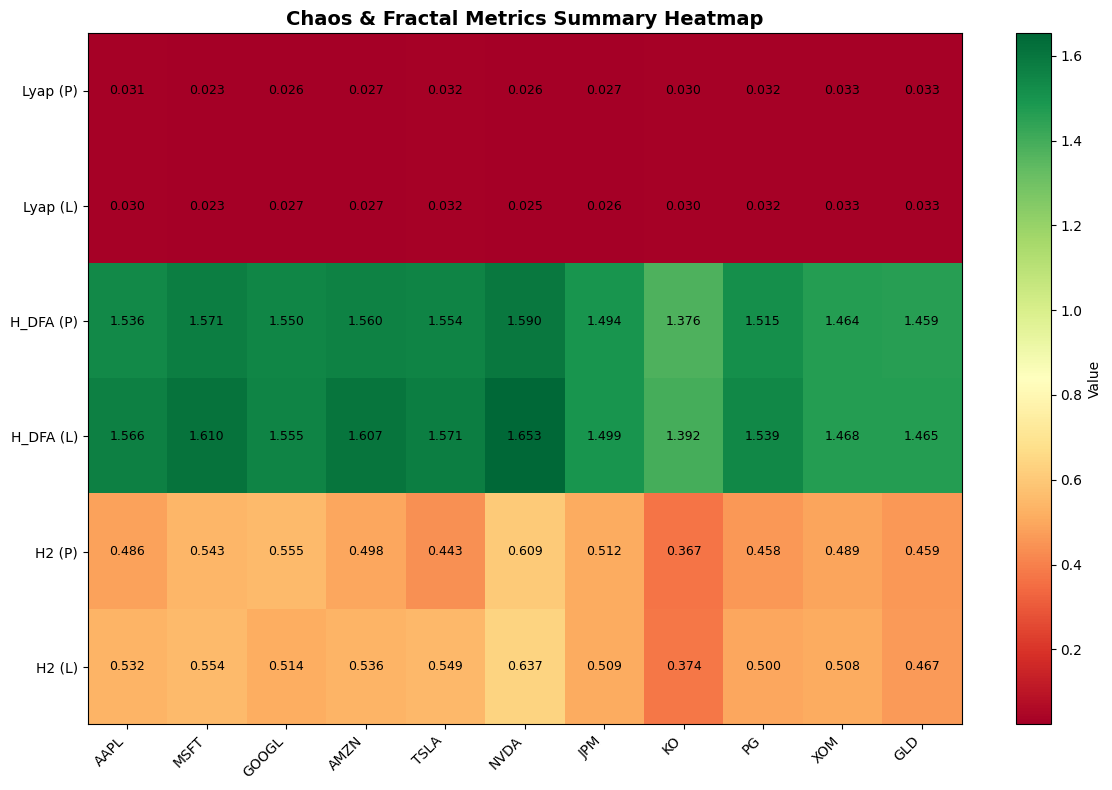

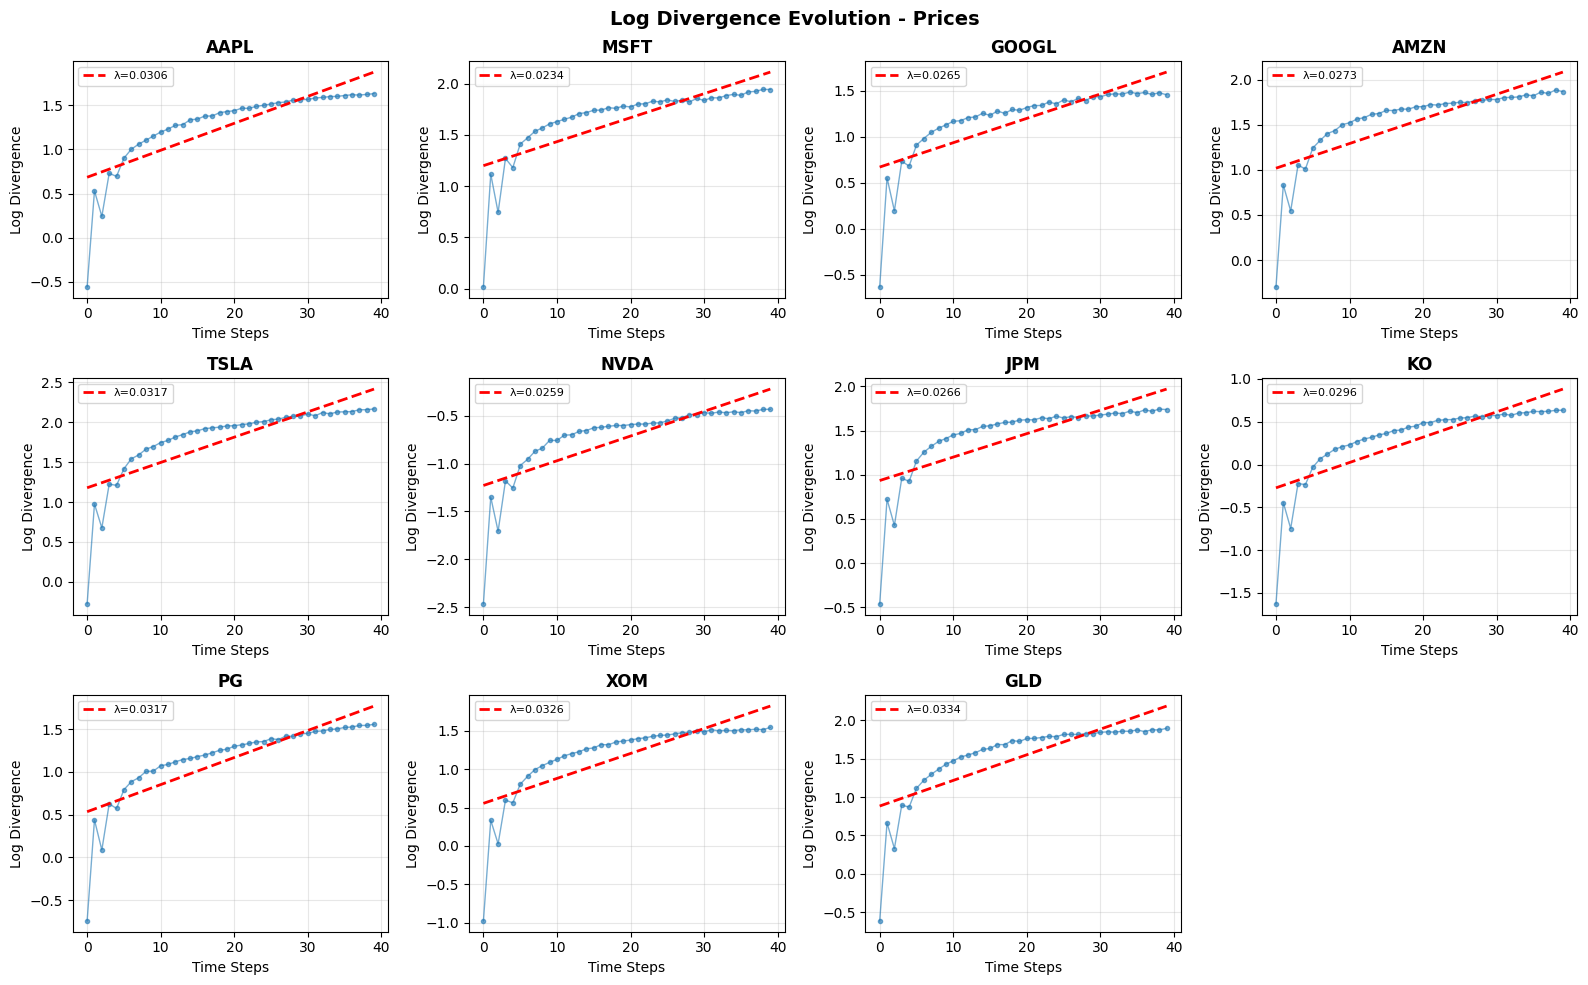

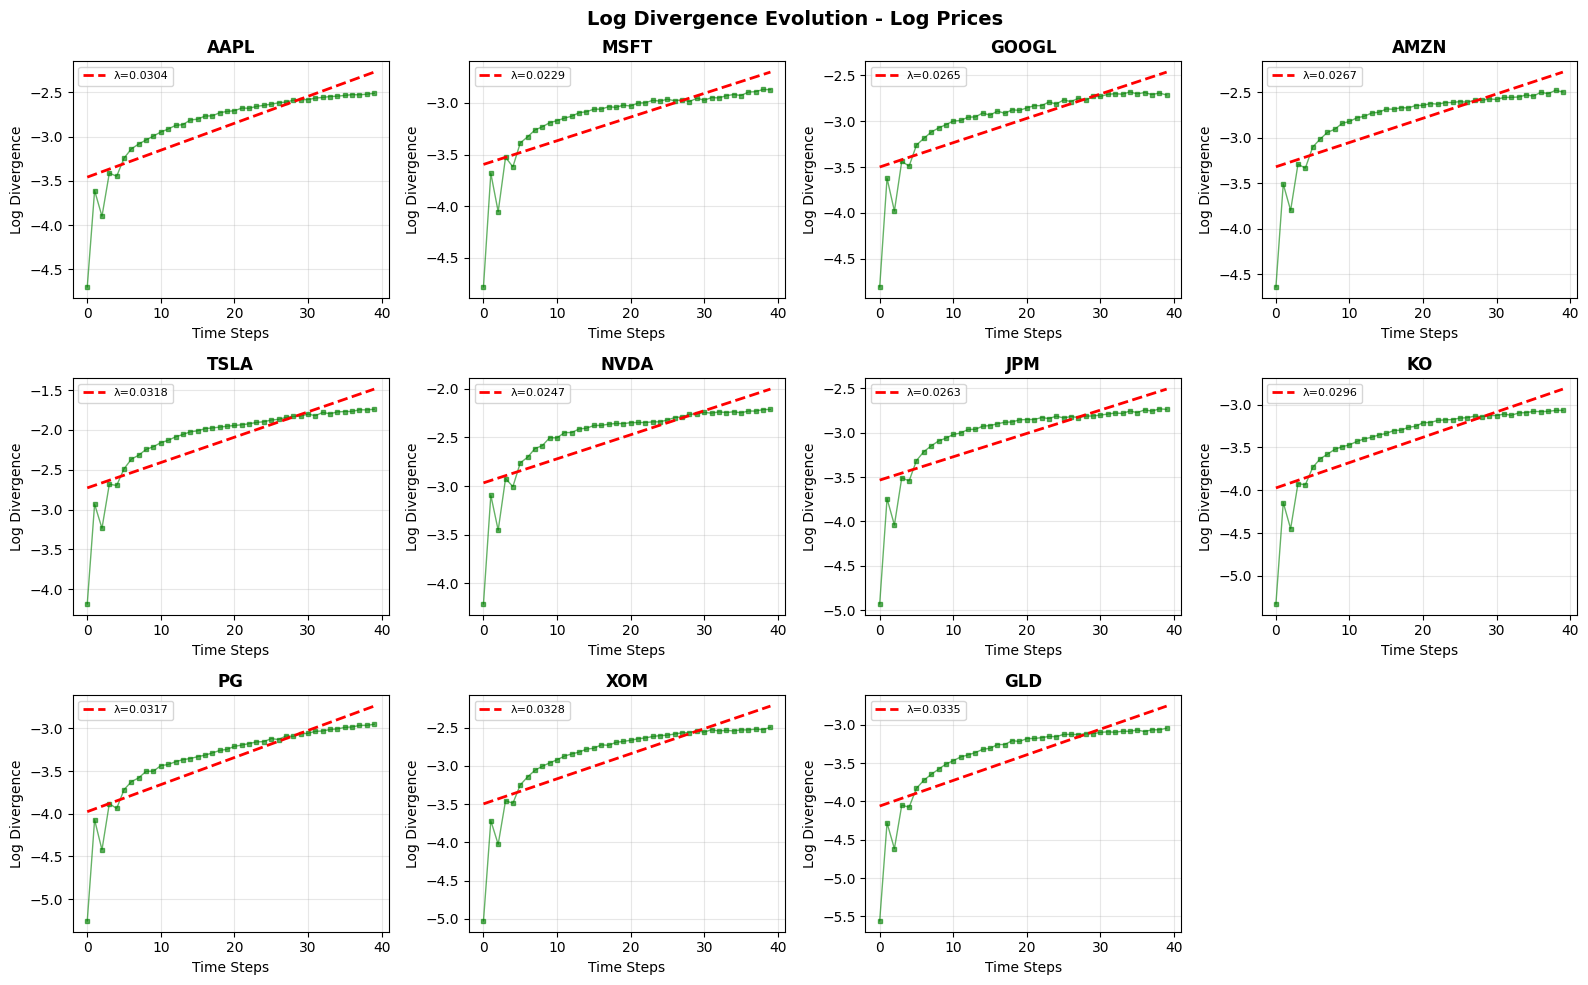

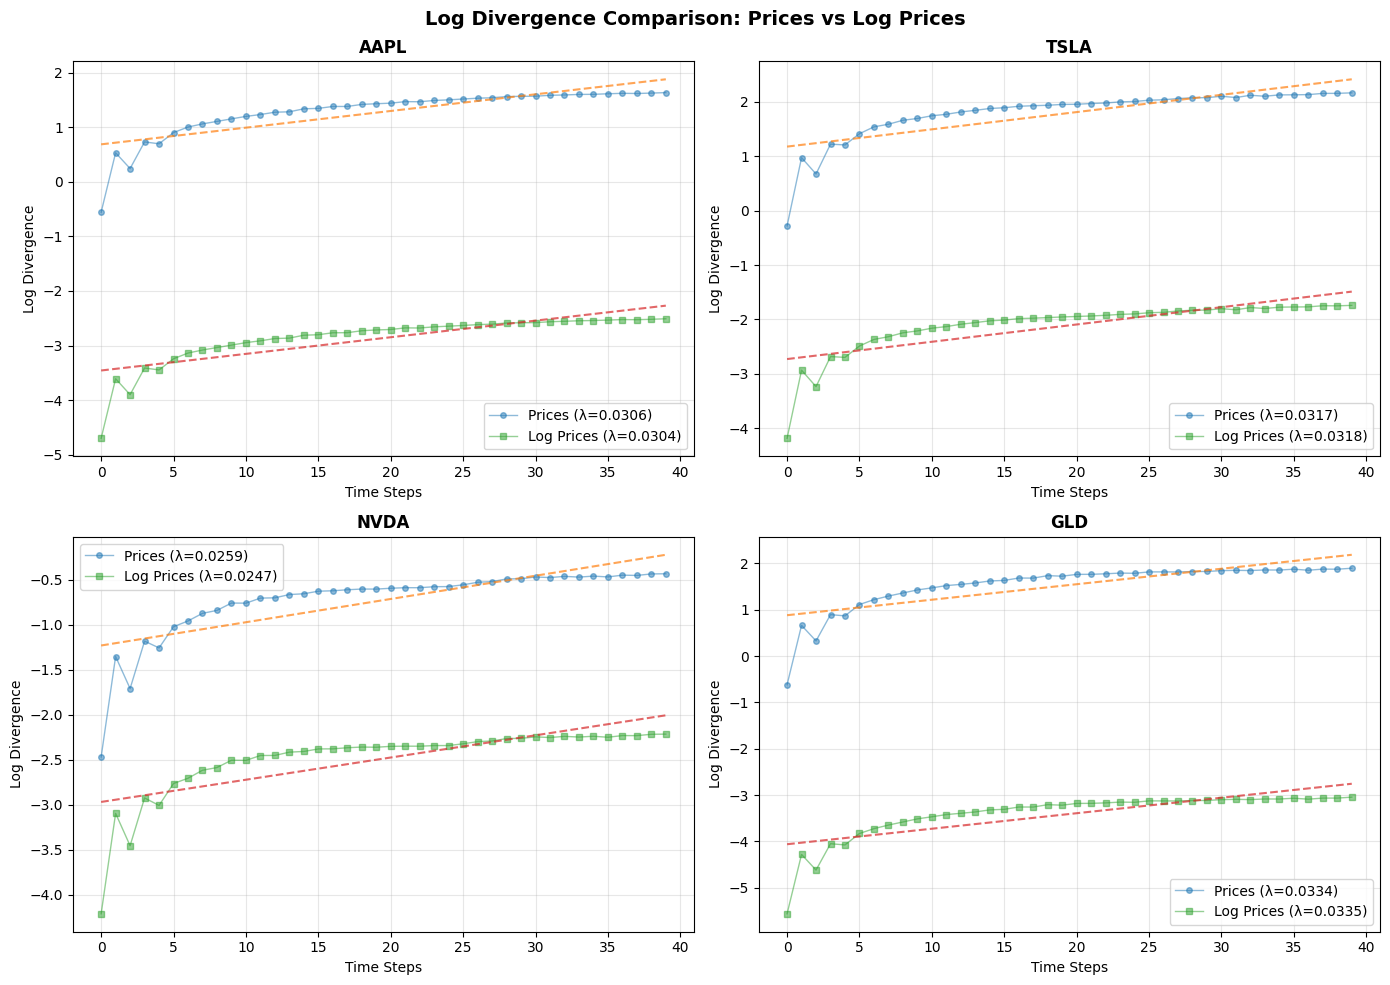


✔ Full chaos + multifractal analysis complete with enhanced visualizations.


In [51]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress
from sklearn.neighbors import NearestNeighbors
import warnings

warnings.filterwarnings("ignore")

# =====================================================
# PARAMETERS
# =====================================================

START = "2015-01-01"
END   = "2024-01-01"

TICKERS = [
    "AAPL", "MSFT", "GOOGL", "AMZN", "TSLA",
    "NVDA", "JPM", "KO", "PG", "XOM", "GLD"
]

# Multifractal
q_vals = np.array([0.5, 1, 2, 3, 4, 5])
s_vals = np.unique(np.logspace(1, 2.3, 18).astype(int))


# =====================================================
# LYAPUNOV EXPONENT (ROSENSTEIN METHOD)
# =====================================================
def lyapunov_rosenstein(x, emb_dim=3, lag=2, max_t=40):
    
    # Force 1D clean array
    x = np.asarray(x).flatten()
    x = x[np.isfinite(x)]

    if len(x) < 600:
        return np.nan, None, None

    # Phase space size
    N = len(x) - (emb_dim - 1) * lag

    if N < 300:
        return np.nan, None, None

    # Phase space reconstruction
    Y = np.zeros((N, emb_dim))

    for i in range(emb_dim):
        Y[:, i] = x[i * lag : i * lag + N]

    # Nearest neighbors
    nn = NearestNeighbors(n_neighbors=2).fit(Y)
    _, idx = nn.kneighbors(Y)

    neighbors = idx[:, 1]

    divergence = np.zeros(max_t)

    for k in range(max_t):

        max_idx = N - k

        if max_idx <= 10:
            divergence[k] = np.nan
            continue

        dists = []

        for i in range(max_idx):

            j = neighbors[i]

            if j + k >= N:
                continue

            d = np.linalg.norm(
                Y[i + k] - Y[j + k]
            )

            if d > 1e-10 and np.isfinite(d):
                dists.append(np.log(d))

        if len(dists) < 10:
            divergence[k] = np.nan
        else:
            divergence[k] = np.mean(dists)

    # Time index
    t = np.arange(len(divergence))

    mask = np.isfinite(divergence)

    if np.sum(mask) < 10:
        return np.nan, None, None

    # Linear fit = Lyapunov exponent
    slope, _, _, _, _ = linregress(
        t[mask],
        divergence[mask]
    )

    return slope, t, divergence

# =====================================================
# HURST EXPONENT (DFA)
# =====================================================

def hurst_dfa(x):
    x = np.asarray(x)

    if len(x) < 400:
        return np.nan

    y = np.cumsum(x - np.mean(x))
    scales = np.unique(np.logspace(1, np.log10(len(y)//4), 14).astype(int))

    F = []
    S = []

    for s in scales:
        if s < 10:
            continue

        n = len(y) // s
        if n < 2:
            continue

        rms = []
        for i in range(n):
            seg = y[i*s:(i+1)*s]
            t = np.arange(len(seg))
            coeff = np.polyfit(t, seg, 1)
            trend = np.polyval(coeff, t)
            rms.append(np.sqrt(np.mean((seg - trend)**2)))

        rms = np.array(rms)
        if np.all(rms > 0):
            F.append(np.mean(rms))
            S.append(s)

    if len(F) < 5:
        return np.nan

    slope, _, _, _, _ = linregress(np.log(S), np.log(F))
    return slope


# =====================================================
# MULTIFRACTAL STRUCTURE FUNCTIONS
# =====================================================

def structure_function(x, q, s):
    if s >= len(x):
        return np.nan
    dx = np.abs(x[s:] - x[:-s])
    return np.mean(dx**q)


def multifractal_analysis(x):
    K = np.zeros((len(q_vals), len(s_vals)))

    for i, q in enumerate(q_vals):
        for j, s in enumerate(s_vals):
            K[i, j] = structure_function(x, q, s)

    Hq, tau_q = [], []

    for i, q in enumerate(q_vals):
        valid = np.isfinite(K[i]) & (K[i] > 0)
        if np.sum(valid) < 4:
            Hq.append(np.nan)
            tau_q.append(np.nan)
            continue

        slope, _, _, _, _ = linregress(
            np.log(s_vals[valid]),
            np.log(K[i][valid])
        )

        H = slope / q
        tau = q * H - 1
        Hq.append(H)
        tau_q.append(tau)

    Hq = np.array(Hq)
    tau_q = np.array(tau_q)

    return Hq, tau_q


# =====================================================
# DOWNLOAD DATA
# =====================================================

print("Downloading daily data...")
data = {}

for t in TICKERS:
    df = yf.download(t, start=START, end=END, progress=False)

    prices = df["Close"].values.flatten()
    prices = prices[np.isfinite(prices)]

    data[t] = prices

print("Download complete.\n")



# =====================================================
# ANALYSIS
# =====================================================

results = {}

for t in TICKERS:
    prices = data[t]
    log_prices = np.log(prices)

    Hq_p, tau_p = multifractal_analysis(prices)
    Hq_l, tau_l = multifractal_analysis(log_prices)
    
    lyap_p, time_p, div_p = lyapunov_rosenstein(prices)
    lyap_l, time_l, div_l = lyapunov_rosenstein(log_prices)

    results[t] = {
        "H2_p": Hq_p[np.where(q_vals == 2)[0][0]],
        "H2_l": Hq_l[np.where(q_vals == 2)[0][0]],
        "H_dfa_p": hurst_dfa(prices),
        "H_dfa_l": hurst_dfa(log_prices),
        "lyap_p": lyap_p,
        "lyap_l": lyap_l,
        "Hq_p": Hq_p,
        "Hq_l": Hq_l,
        "tau_p": tau_p,
        "tau_l": tau_l,
        "time_p": time_p,
        "div_p": div_p,
        "time_l": time_l,
        "div_l": div_l,
    }

    print(
        f"{t:5s} | "
        f"P: H2={results[t]['H2_p']:.3f}, Hdfa={results[t]['H_dfa_p']:.3f}, λ={results[t]['lyap_p']:.4f} | "
        f"L: H2={results[t]['H2_l']:.3f}, Hdfa={results[t]['H_dfa_l']:.3f}, λ={results[t]['lyap_l']:.4f}"
    )


# =====================================================
# VISUALIZATION
# =====================================================

labels = list(results.keys())

lyap_p = [results[t]["lyap_p"] for t in labels]
lyap_l = [results[t]["lyap_l"] for t in labels]

# Plot 1: Lyapunov Exponents
plt.figure(figsize=(10, 6))
plt.barh(labels, lyap_p, alpha=0.7, label="Prices")
plt.barh(labels, lyap_l, alpha=0.7, label="Log Prices")
plt.axvline(0, color="black", lw=2)
plt.title("Lyapunov Exponent (Daily Data)")
plt.xlabel("Lyapunov Exponent")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 2: Hurst Exponents Comparison
H2_p = [results[t]["H2_p"] for t in labels]
H2_l = [results[t]["H2_l"] for t in labels]
Hdfa_p = [results[t]["H_dfa_p"] for t in labels]
Hdfa_l = [results[t]["H_dfa_l"] for t in labels]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(labels, H2_p, alpha=0.7, label="Prices (H2)")
axes[0].barh(labels, H2_l, alpha=0.7, label="Log Prices (H2)")
axes[0].axvline(0.5, color="red", linestyle="--", lw=1, label="Random Walk")
axes[0].set_title("Multifractal H(q=2)")
axes[0].set_xlabel("Hurst Exponent")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].barh(labels, Hdfa_p, alpha=0.7, label="Prices (DFA)")
axes[1].barh(labels, Hdfa_l, alpha=0.7, label="Log Prices (DFA)")
axes[1].axvline(0.5, color="red", linestyle="--", lw=1, label="Random Walk")
axes[1].set_title("DFA Hurst Exponent")
axes[1].set_xlabel("Hurst Exponent")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Plot 3: Multifractal Spectrum H(q) for each ticker
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for idx, t in enumerate(labels):
    ax = axes[idx]
    Hq_p = results[t]["Hq_p"]
    Hq_l = results[t]["Hq_l"]
    
    valid_p = np.isfinite(Hq_p)
    valid_l = np.isfinite(Hq_l)
    
    ax.plot(q_vals[valid_p], Hq_p[valid_p], 'o-', label="Prices", alpha=0.7)
    ax.plot(q_vals[valid_l], Hq_l[valid_l], 's-', label="Log Prices", alpha=0.7)
    ax.axhline(0.5, color="red", linestyle="--", lw=1, alpha=0.5)
    ax.set_title(t, fontweight='bold')
    ax.set_xlabel("q")
    ax.set_ylabel("H(q)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

# Hide extra subplot
axes[-1].axis('off')

plt.suptitle("Multifractal Spectrum H(q) by Ticker", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Plot 4: Chaos vs Memory Scatter Plot
fig, ax = plt.subplots(figsize=(10, 8))

for t in labels:
    lyap = results[t]["lyap_l"]
    hurst = results[t]["H_dfa_l"]
    ax.scatter(lyap, hurst, s=100, alpha=0.7)
    ax.annotate(t, (lyap, hurst), fontsize=9, alpha=0.8)

ax.axhline(0.5, color="red", linestyle="--", lw=1, alpha=0.5, label="H=0.5 (Random)")
ax.axvline(0, color="blue", linestyle="--", lw=1, alpha=0.5, label="λ=0 (Stable)")
ax.set_xlabel("Lyapunov Exponent (Log Prices)", fontsize=12)
ax.set_ylabel("Hurst Exponent DFA (Log Prices)", fontsize=12)
ax.set_title("Chaos vs Memory: Lyapunov vs Hurst", fontsize=14, fontweight='bold')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Plot 5: Price Time Series with Normalized Scale
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()

for idx, t in enumerate(labels):
    ax = axes[idx]
    prices = data[t]
    normalized = (prices - prices.min()) / (prices.max() - prices.min())
    ax.plot(normalized, alpha=0.7, linewidth=1)
    ax.set_title(f"{t} (λ={results[t]['lyap_l']:.3f}, H={results[t]['H_dfa_l']:.2f})", fontsize=10)
    ax.set_ylabel("Normalized Price")
    ax.grid(alpha=0.3)

axes[-1].axis('off')

plt.suptitle("Normalized Price Time Series (2015-2024)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Plot 6: Summary Heatmap
fig, ax = plt.subplots(figsize=(12, 8))

metrics_data = np.array([
    [results[t]["lyap_p"] for t in labels],
    [results[t]["lyap_l"] for t in labels],
    [results[t]["H_dfa_p"] for t in labels],
    [results[t]["H_dfa_l"] for t in labels],
    [results[t]["H2_p"] for t in labels],
    [results[t]["H2_l"] for t in labels],
])

im = ax.imshow(metrics_data, aspect='auto', cmap='RdYlGn', interpolation='nearest')
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticks(range(6))
ax.set_yticklabels(["Lyap (P)", "Lyap (L)", "H_DFA (P)", "H_DFA (L)", "H2 (P)", "H2 (L)"])

for i in range(metrics_data.shape[0]):
    for j in range(metrics_data.shape[1]):
        text = ax.text(j, i, f"{metrics_data[i, j]:.3f}",
                      ha="center", va="center", color="black", fontsize=9)

plt.colorbar(im, ax=ax, label="Value")
plt.title("Chaos & Fractal Metrics Summary Heatmap", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Plot 7: Log Divergence Plots for Prices
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for idx, t in enumerate(labels):
    ax = axes[idx]
    time_data = results[t]["time_p"]
    div_data = results[t]["div_p"]
    lyap = results[t]["lyap_p"]
    
    if time_data is not None and div_data is not None:
        mask = np.isfinite(div_data)
        if np.sum(mask) > 0:
            ax.plot(time_data[mask], div_data[mask], 'o-', alpha=0.6, markersize=3, linewidth=1)
            
            # Calculate and plot fitted line using linear regression
            t_fit = time_data[mask]
            d_fit = div_data[mask]
            slope, intercept, _, _, _ = linregress(t_fit, d_fit)
            ax.plot(t_fit, slope * t_fit + intercept, 
                    'r--', linewidth=2, label=f'λ={slope:.4f}')
    
    ax.set_title(t, fontweight='bold')
    ax.set_xlabel("Time Steps")
    ax.set_ylabel("Log Divergence")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[-1].axis('off')

plt.suptitle("Log Divergence Evolution - Prices", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Plot 8: Log Divergence Plots for Log Prices
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for idx, t in enumerate(labels):
    ax = axes[idx]
    time_data = results[t]["time_l"]
    div_data = results[t]["div_l"]
    lyap = results[t]["lyap_l"]
    
    if time_data is not None and div_data is not None:
        mask = np.isfinite(div_data)
        if np.sum(mask) > 0:
            ax.plot(time_data[mask], div_data[mask], 's-', alpha=0.6, markersize=3, linewidth=1, color='green')
            
            # Calculate and plot fitted line using linear regression
            t_fit = time_data[mask]
            d_fit = div_data[mask]
            slope, intercept, _, _, _ = linregress(t_fit, d_fit)
            ax.plot(t_fit, slope * t_fit + intercept, 
                    'r--', linewidth=2, label=f'λ={slope:.4f}')
    
    ax.set_title(t, fontweight='bold')
    ax.set_xlabel("Time Steps")
    ax.set_ylabel("Log Divergence")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[-1].axis('off')

plt.suptitle("Log Divergence Evolution - Log Prices", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Plot 9: Combined Log Divergence Comparison (Selected Tickers)
selected_tickers = ["AAPL", "TSLA", "NVDA", "GLD"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, t in enumerate(selected_tickers):
    ax = axes[idx]
    
    # Prices
    time_p = results[t]["time_p"]
    div_p = results[t]["div_p"]
    lyap_p = results[t]["lyap_p"]
    
    # Log Prices
    time_l = results[t]["time_l"]
    div_l = results[t]["div_l"]
    lyap_l = results[t]["lyap_l"]
    
    if time_p is not None and div_p is not None:
        mask_p = np.isfinite(div_p)
        if np.sum(mask_p) > 0:
            ax.plot(time_p[mask_p], div_p[mask_p], 'o-', alpha=0.5, 
                    markersize=4, linewidth=1, label=f'Prices (λ={lyap_p:.4f})')
            # Fitted line for prices
            t_fit_p = time_p[mask_p]
            d_fit_p = div_p[mask_p]
            slope_p, int_p, _, _, _ = linregress(t_fit_p, d_fit_p)
            ax.plot(t_fit_p, slope_p * t_fit_p + int_p, '--', linewidth=1.5, alpha=0.7)
    
    if time_l is not None and div_l is not None:
        mask_l = np.isfinite(div_l)
        if np.sum(mask_l) > 0:
            ax.plot(time_l[mask_l], div_l[mask_l], 's-', alpha=0.5, 
                    markersize=4, linewidth=1, label=f'Log Prices (λ={lyap_l:.4f})')
            # Fitted line for log prices
            t_fit_l = time_l[mask_l]
            d_fit_l = div_l[mask_l]
            slope_l, int_l, _, _, _ = linregress(t_fit_l, d_fit_l)
            ax.plot(t_fit_l, slope_l * t_fit_l + int_l, '--', linewidth=1.5, alpha=0.7)
    
    ax.set_title(t, fontweight='bold', fontsize=12)
    ax.set_xlabel("Time Steps")
    ax.set_ylabel("Log Divergence")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Log Divergence Comparison: Prices vs Log Prices", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✔ Full chaos + multifractal analysis complete with enhanced visualizations.")